In [11]:
# ** TASK 5- Titanic ML Prediction System**

## Load Titanic Dataset:

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns

# Load original Titanic dataset
df = sns.load_dataset('titanic')

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

First 5 Rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


## EDA-Exploratory Data Analysis:

In [13]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check survival distribution
print("\nSurvival Counts:")
print(df['survived'].value_counts())

# Check survival percentages
print("\nSurvival Percentages:")
print(df['survived'].value_counts(normalize=True) * 100)

Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Survival Counts:
survived
0    549
1    342
Name: count, dtype: int64

Survival Percentages:
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


## Visualise Passenger Survival:


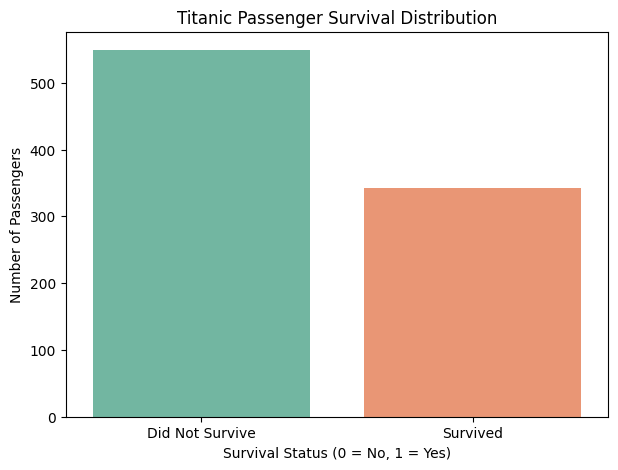

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='survived',
    hue='survived',
    palette='Set2',
    legend=False
)

plt.title('Titanic Passenger Survival Distribution')
plt.xlabel('Survival Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])

plt.show()

In [15]:
# Select features
X = df[['pclass', 'sex', 'age', 'sibsp',
        'parch', 'fare', 'embarked']]

# Select target
y = df['survived']

# Display information
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSelected Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features Shape: (891, 7)
Target Shape: (891,)

Selected Features:
   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


## Train Test split

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Survival Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Survival Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (712, 7)
Testing Features: (179, 7)

Training Target: (712,)
Testing Target: (179,)

Training Survival Distribution:
survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64

Testing Survival Distribution:
survived
0    61.452514
1    38.547486
Name: proportion, dtype: float64


## Preprocessing pipeline

### Import the tools:

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

### Define Column groups:

In [18]:
# Numerical columns
numerical_features = [
    'pclass', 'age', 'sibsp', 'parch', 'fare'
]

# Categorical columns
categorical_features = [
    'sex', 'embarked'
]

### Create Numerical Preprocessing Pipeline:
Operations:
1. Fill missing values using median.
2. Scale values using StandardScaler.

In [19]:
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

### Create Categorical Preprocessing Pipleine:
Operations:
1. Fill missing values using most frequent value.
2. Convert categories into numerical representations using OneHotEncoder.

In [20]:
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

### Combine both pipelines:

In [21]:
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

## Logistic Regresssion:
It is a classiifcation algorithm that helps to predict that whetehr the passenger survived or not with the help of input features.



### Import Logistic Regression:

In [22]:
from sklearn.linear_model import LogisticRegression

### Create the complete ML pipeline:

In [23]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

### Train the model

In [25]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


### Generate Predictions:

In [26]:
# Generate predictions on testing data
y_pred = model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

First 10 Actual Values:
[0 0 1 0 1 1 1 0 0 0]

First 10 Predicted Values:
[0 0 0 0 1 0 1 0 0 0]


## Evaluate Logistic Regression:

### Import Evaluation Tool:

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

### Calculate performance metrics:

In [28]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Logistic Model Performance:")
print("--------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Model Performance:
--------------------------
Accuracy:  0.8045
Precision: 0.7931
Recall:    0.6667
F1 Score:  0.7244


In [29]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



### Confuson Matrix on Logistic Regression Model Prediction:
It tells how much the prediction of passengers is correect in model anfd how mnay it got wrong.

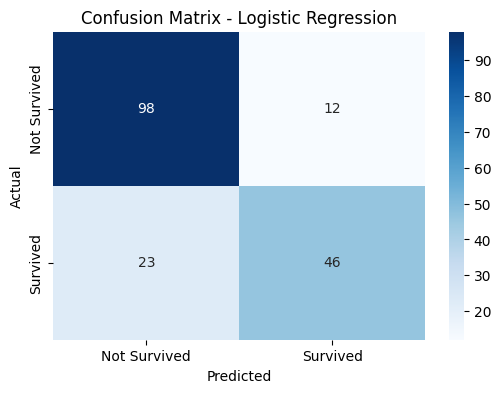

In [30]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

## Decision Tree:
It helps in learning non linear patterns and decision rules.

### Import Decision Tree:

In [31]:
from sklearn.tree import DecisionTreeClassifier

### Create Decision Tree Pipeline:

In [32]:
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

### Train the Model:

In [33]:
dt_model.fit(X_train, y_train)

print("Decision Tree training completed successfully!")

Decision Tree training completed successfully!


### Generate Predictions:

In [34]:
dt_pred = dt_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Decision Tree Predictions:")
print(dt_pred[:10])

First 10 Actual Values:
[0 0 1 0 1 1 1 0 0 0]

First 10 Decision Tree Predictions:
[0 0 0 0 1 0 1 1 0 0]


## Evaluate Decision Tree:

In [35]:
# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print("Decision Tree Performance:")
print("--------------------------")
print(f"Accuracy:  {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall:    {dt_recall:.4f}")
print(f"F1 Score:  {dt_f1:.4f}")

Decision Tree Performance:
--------------------------
Accuracy:  0.8156
Precision: 0.7903
Recall:    0.7101
F1 Score:  0.7481


### Classification Report:

In [36]:
print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.83      0.88      0.85       110
           1       0.79      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



### Confusion Matrix on Decison Tree Model Prediction:

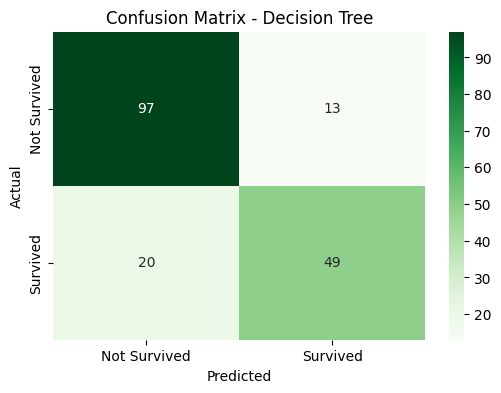

In [37]:
dt_cm = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

## Check for Overfitting:
Comapre Trainign Accuracy with testing Accuracy for both models.

In [38]:
# Logistic Regression accuracy
lr_train_accuracy = model.score(X_train, y_train)
lr_test_accuracy = model.score(X_test, y_test)

# Decision Tree accuracy
dt_train_accuracy = dt_model.score(X_train, y_train)
dt_test_accuracy = dt_model.score(X_test, y_test)

print("Logistic Regression:")
print(f"Training Accuracy: {lr_train_accuracy:.4f}")
print(f"Testing Accuracy:  {lr_test_accuracy:.4f}")

print("\nDecision Tree:")
print(f"Training Accuracy: {dt_train_accuracy:.4f}")
print(f"Testing Accuracy:  {dt_test_accuracy:.4f}")

Logistic Regression:
Training Accuracy: 0.8076
Testing Accuracy:  0.8045

Decision Tree:
Training Accuracy: 0.9831
Testing Accuracy:  0.8156


## Improve Decision Tree using Hyperparameter Tuning:
**Hyperparameter Tuning:**
Machine learning algorithms have settings that we can adjust to improve their performance.

### Import GridSearchCV:

In [39]:
from sklearn.model_selection import GridSearchCV

### Define parameter combinations:

In [40]:
param_grid = {
    'classifier__max_depth': [3, 5, 7, 10, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

### Configure GridSearchCV:

In [41]:
grid_search = GridSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(random_state=42))
    ]),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

### Find the best parameter:


In [42]:
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Fitting 5 folds for each of 45 candidates, totalling 225 fits
Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10}

Best Cross-Validation F1 Score:
0.7495467447853319


## Evaluate tuned Decision tree:

### Get Best model:

In [43]:
best_dt_model = grid_search.best_estimator_

print("Best Decision Tree model obtained successfully!")

Best Decision Tree model obtained successfully!


### Generate Predictions:

In [44]:
best_dt_pred = best_dt_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Tuned Decision Tree Predictions:")
print(best_dt_pred[:10])

First 10 Actual Values:
[0 0 1 0 1 1 1 0 0 0]

First 10 Tuned Decision Tree Predictions:
[0 0 0 0 1 0 1 1 1 0]


### Evaluate Performance:

In [45]:
best_dt_accuracy = accuracy_score(y_test, best_dt_pred)
best_dt_precision = precision_score(y_test, best_dt_pred)
best_dt_recall = recall_score(y_test, best_dt_pred)
best_dt_f1 = f1_score(y_test, best_dt_pred)

print("Tuned Decision Tree Performance:")
print("--------------------------------")
print(f"Accuracy:  {best_dt_accuracy:.4f}")
print(f"Precision: {best_dt_precision:.4f}")
print(f"Recall:    {best_dt_recall:.4f}")
print(f"F1 Score:  {best_dt_f1:.4f}")

Tuned Decision Tree Performance:
--------------------------------
Accuracy:  0.7933
Precision: 0.7581
Recall:    0.6812
F1 Score:  0.7176


### Check training Vs Testing Accuracy:

In [46]:
print("Tuned Decision Tree:")
print(f"Training Accuracy: {best_dt_model.score(X_train, y_train):.4f}")
print(f"Testing Accuracy:  {best_dt_model.score(X_test, y_test):.4f}")

Tuned Decision Tree:
Training Accuracy: 0.9101
Testing Accuracy:  0.7933


## Final Model Comparison Visualization:

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.8045     0.7931  0.6667    0.7244
1        Decision Tree    0.8156     0.7903  0.7101    0.7481
2  Tuned Decision Tree    0.7933     0.7581  0.6812    0.7176


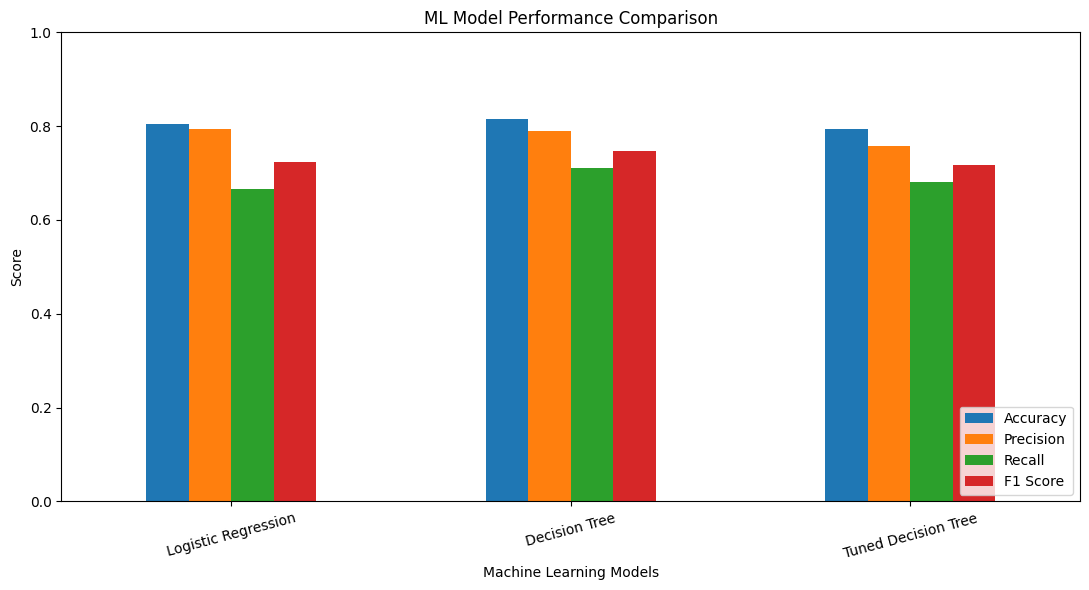

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

comparison_df = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Tuned Decision Tree'
    ],
    'Accuracy': [
        accuracy,
        dt_accuracy,
        best_dt_accuracy
    ],
    'Precision': [
        precision,
        dt_precision,
        best_dt_precision
    ],
    'Recall': [
        recall,
        dt_recall,
        best_dt_recall
    ],
    'F1 Score': [
        f1,
        dt_f1,
        best_dt_f1
    ]
})

print(comparison_df.round(4))

comparison_df.set_index('Model').plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('ML Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Saving the Trainned Model

In [48]:
import joblib

### Save complete pipeline:

In [49]:
joblib.dump(model, 'titanic_survival_model.pkl')

print("Model saved successfully!")

Model saved successfully!


### Test the saved Model:

In [50]:
# Load saved model
loaded_model = joblib.load('titanic_survival_model.pkl')

# Make predictions using loaded model
saved_model_predictions = loaded_model.predict(X_test)

print("Loaded Model Predictions:")
print(saved_model_predictions[:10])

print("\nOriginal Model Accuracy:",
      accuracy_score(y_test, y_pred))

print("Loaded Model Accuracy:",
      accuracy_score(y_test, saved_model_predictions))

Loaded Model Predictions:
[0 0 0 0 1 0 1 0 0 0]

Original Model Accuracy: 0.8044692737430168
Loaded Model Accuracy: 0.8044692737430168
